# Improving Neural Network Learning

Training a neural network involves more than just running gradient descent. Several techniques can dramatically affect how fast the network learns, how well it generalises to unseen data, and whether it gets stuck or diverges.

This notebook explores the most important ones using a **synthetic regression dataset** built from a combination of trigonometric and logarithmic functions with added Gaussian noise.

## 1. Synthetic Dataset

Import the required libraries:

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Generate 1000 evenly-spaced points over $[0, 4\pi]$ and compute the target function:

$$y_{\text{true}}(x) = \sin(x) + 0.5\cos(2x) + 0.3\ln(x+1)$$

Then add Gaussian noise $\varepsilon \sim \mathcal{N}(0,\, 0.2^2)$ to simulate real-world measurements:

$$y_{\text{noisy}}(x) = y_{\text{true}}(x) + \varepsilon$$

In [15]:
np.random.seed(42)

x       = np.linspace(0, 4 * np.pi, 1000)
y_true  = np.sin(x) + 0.5 * np.cos(2 * x) + 0.3 * np.log(x + 1)
noise   = np.random.normal(0, 0.2, size=x.shape)
y_noisy = y_true + noise

df = pd.DataFrame({'x': x, 'y_true': y_true, 'y_noisy': y_noisy})
df.head()

,x,y_true,y_noisy
0,0.000000,0.500000,0.599343
1,0.012579,0.516171,0.488518
2,0.025158,0.531976,0.661514
3,0.037737,0.547417,0.852023
4,0.050316,0.562492,0.515662


Visualise the clean target function and the noisy observations:

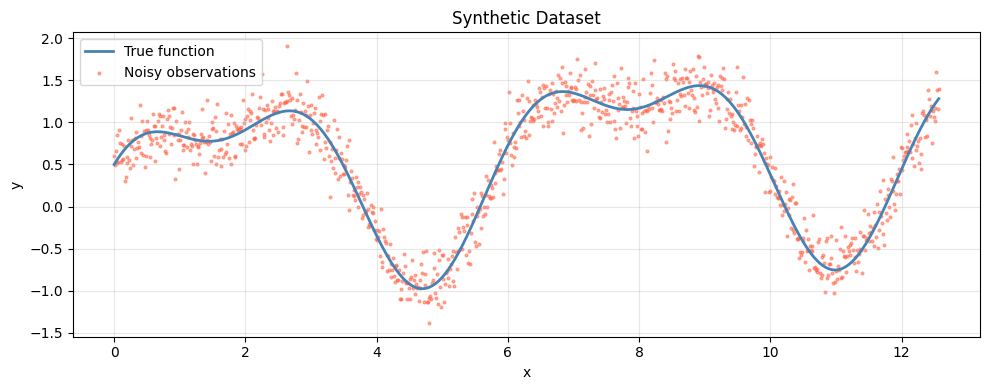

In [16]:
plt.figure(figsize=(10, 4))
plt.plot(df['x'], df['y_true'],  color='steelblue', linewidth=2, label='True function')
plt.scatter(df['x'], df['y_noisy'], color='tomato', s=4, alpha=0.5, label='Noisy observations')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Synthetic Dataset')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

## 2. Train / Validation / Test Split

In [17]:
from sklearn.model_selection import train_test_split

X = df[['x']].values
y = df['y_noisy'].values.reshape(-1, 1)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val,   X_test,  y_val,  y_test  = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print(f'Train: {X_train.shape[0]}  |  Val: {X_val.shape[0]}  |  Test: {X_test.shape[0]}')

Train: 700  |  Val: 150  |  Test: 150


## 3. Input Normalisation

The input $x$ spans $[0,\, 4\pi] \approx [0,\, 12.6]$. Feeding raw values of this magnitude into a network with small random weights produces very large pre-activations, which saturate sigmoid/tanh neurons and slow down learning.

**Standard score normalisation** rescales each feature to have zero mean and unit variance:

$$x_{\text{norm}} = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

The statistics ($\mu$, $\sigma$) are computed **on the training set only** and then applied to validation and test sets — this prevents information from leaking into the model.

In [18]:
# Use the training set statistics to normalize all sets
mu    = X_train.mean()
sigma = X_train.std()

X_train_n = (X_train - mu) / sigma
X_val_n   = (X_val   - mu) / sigma
X_test_n  = (X_test  - mu) / sigma

print(f'Train mean: {X_train_n.mean():.4f}  std: {X_train_n.std():.4f}')

Train mean: -0.0000  std: 1.0000


### Why normalize?

If we don't normalize the inputs our cost function will be deep and its shape will be inconsistent (elongated) then optimizing it will take a long time.
But if we normalize it the opposite will occur. The shape of the cost function will be consistent (look more symmetric like circle in 2D example) and we can use a larger learning rate alpha - the optimization will be faster.

So, if you normalize your inputs this will **speed up the training** process a lot.

## 4. Baseline Network

A fully-connected network with two hidden layers and **ReLU** activations. The output layer is linear (no activation) since this is a regression task.

Architecture: $1 \to 32 \to 32 \to 1$

In [19]:
def relu(z):      
    return np.maximum(0, z)

def relu_deriv(z):  
    return (z > 0).astype(float)

**He initialisation** sets the initial weights by drawing from $\mathcal{N}\!\left(0,\, \sqrt{2/n_{\text{in}}}\right)$, which keeps the variance of activations stable across layers when using ReLU.

In [20]:
def init_params(layer_sizes, seed=0):
    np.random.seed(seed)
    params = {}
    for i in range(1, len(layer_sizes)):
        fan_in = layer_sizes[i - 1]
        params[f'W{i}'] = np.random.randn(fan_in, layer_sizes[i]) * np.sqrt(2 / fan_in)
        params[f'b{i}'] = np.zeros((1, layer_sizes[i]))
    return params

layer_sizes = [1, 32, 32, 1]
params = init_params(layer_sizes)
print({k: v.shape for k, v in params.items()})

{'W1': (1, 32), 'b1': (1, 32), 'W2': (32, 32), 'b2': (1, 32), 'W3': (32, 1), 'b3': (1, 1)}


#### Weight Initialization for Deep Networks

Proper weight initialization is one of the key techniques used to mitigate the vanishing and exploding gradients problem in deep neural networks. The core idea is that the way we choose the initial values of the weights strongly affects how signals and gradients propagate through many layers.

To understand this, consider a single neuron where the linear combination is given by \( Z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n \). If the number of input features \( n \) is large, then using weights that are too large can easily cause the output to grow uncontrollably as it propagates through layers, leading to exploding activations. For this reason, we want the variance of the weights to scale inversely with the number of input connections, typically around \( 1/n_x \), so that the signal remains stable as it moves forward through the network.

This idea leads to different initialization strategies. For activations like tanh, a common choice is Xavier initialization, where weights are sampled as:

```python
np.random.randn(shape) * np.sqrt(1 / n[l-1])
```

A more general version proposed by Bengio and collaborators uses:

```python
np.random.randn(shape) * np.sqrt(2 / (n[l-1] + n[l]))
```

For ReLU activations, a particularly effective variant is He initialization:

```python
np.random.randn(shape) * np.sqrt(2 / n[l-1])
```

In practice, the constant in the numerator (such as 1 or 2) can also be treated as a hyperparameter, but these standard forms already provide strong performance and are usually good starting points. 

The vanishing and exploding gradients problem itself arises because, in a very deep network, repeated multiplication by weight matrices can cause activations and gradients to either shrink or grow exponentially with the number of layers.

**Forward pass** — propagate the input through each layer:

$$z^{(l)} = a^{(l-1)} \cdot W^{(l)} + b^{(l)}, \qquad a^{(l)} = \text{ReLU}(z^{(l)})$$

The output layer has no activation: $\hat{y} = z^{(L)}$.

In [21]:
def forward(X, params):
    cache = {'a0': X}
    a = X
    n_layers = len(params) // 2

    for i in range(1, n_layers):        # hidden layers — ReLU
        z = a @ params[f'W{i}'] + params[f'b{i}']
        a = relu(z)
        cache[f'z{i}'] = z
        cache[f'a{i}'] = a

    i = n_layers                        # output layer — linear
    z = a @ params[f'W{i}'] + params[f'b{i}']
    cache[f'z{i}'] = z
    cache[f'a{i}'] = z
    
    return z, cache

**Backward pass** — compute gradients via the chain rule.

Output layer (linear activation):
$$\delta^{(L)} = -(y - \hat{y})$$

Hidden layer $l$ (ReLU):
$$\delta^{(l)} = \left(\delta^{(l+1)} \cdot W^{(l+1)T}\right) \odot \text{ReLU}'(z^{(l)})$$

Weight gradients:
$$\frac{\partial J}{\partial W^{(l)}} = a^{(l-1)T} \cdot \delta^{(l)}, \qquad \frac{\partial J}{\partial b^{(l)}} = \sum \delta^{(l)}$$

In [22]:
def backward(y, y_hat, params, cache):
    m = y.shape[0]
    grads = {}
    n_layers = len(params) // 2
    delta = -(y - y_hat) / m

    for i in range(n_layers, 0, -1):
        grads[f'dW{i}'] = cache[f'a{i-1}'].T @ delta
        grads[f'db{i}'] = delta.sum(axis=0, keepdims=True)

        if i > 1:
            delta = delta @ params[f'W{i}'].T * relu_deriv(cache[f'z{i-1}'])
            
    return grads

Update each weight matrix with the standard gradient descent rule: $W \leftarrow W - \alpha \cdot \nabla_W J$

In [23]:
def update_params(params, grads, lr):
    for key in params:
        params[key] -= lr * grads['d' + key]
        
    return params

**Mean Squared Error** loss:

$$J = \frac{1}{m} \sum_{i=1}^{m} (y_i - \hat{y}_i)^2$$

In [24]:
def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

## 5. Training the Baseline

Train for a fixed number of epochs using full-batch gradient descent. Both training and validation loss are recorded at every epoch to detect overfitting.

In [25]:
import time

def train(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)
        params       = update_params(params, grads, lr)
        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _   = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_base, tl_base, vl_base, t_base = train(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, epochs=2000
)

Final train MSE: 0.2857  |  val MSE: 0.2486  |  time: 1.36s


Plot training and validation loss curves to check for overfitting:

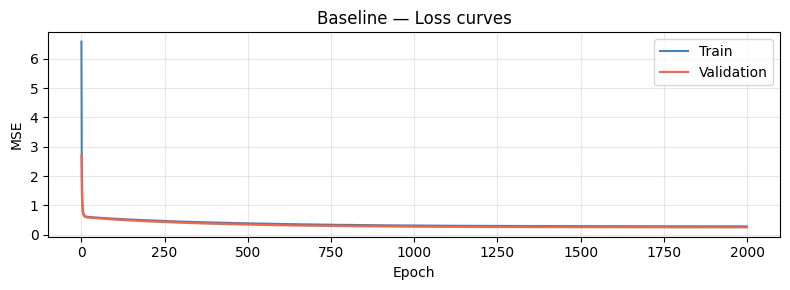

In [26]:
def plot_loss(train_loss, val_loss, title='Loss curves'):
    plt.figure(figsize=(8, 3))
    plt.plot(train_loss, label='Train',      color='steelblue')
    plt.plot(val_loss,   label='Validation', color='tomato')
    plt.xlabel('Epoch'); plt.ylabel('MSE')
    plt.title(title); plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

plot_loss(tl_base, vl_base, title='Baseline — Loss curves')

It's important to print train/validation loss for the bias/variance problem:

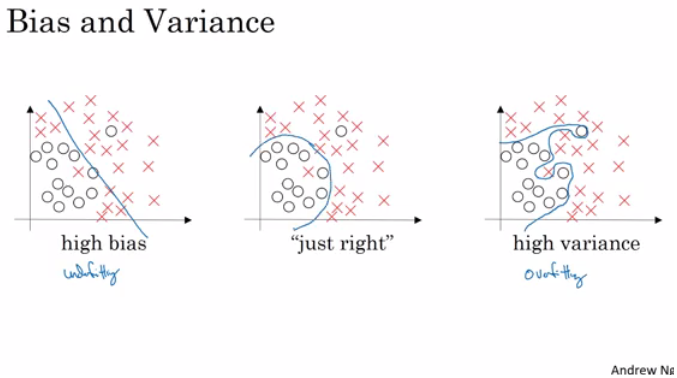

<br>

High variance (overfitting) for example: Training error: 1%, Val error: 11% <br>
high Bias (underfitting) for example: Training error: 15%, Val error: 14% <br>
high Bias (underfitting) && High variance (overfitting) for example: Training error: 15%, Test error: 30% <br>
Best: Training error: 0.5%, Test error: 1% <br>

If your algorithm has a high bias:
- Try to make your NN bigger (size of hidden units, number of layers)
- Try a different model that is suitable for your data.
- Try to run it longer.
- Different (advanced) optimization algorithms. <br>

If your algorithm has a high variance:
- More data.
- Try regularization.
- Try a different model that is suitable for your data. <br>

You should try the previous two points until you have a low bias and low variance.
In the older days before deep learning, there was a "Bias/variance tradeoff". But because now you have more options/tools for solving the bias and variance problem its really helpful to use deep learning.
Training a bigger neural network never hurts.

---

# Logistic Regression as Cost Function

Instead of using Mean Squared Error (MSE), logistic regression typically uses a different cost function called **log loss** (or **cross-entropy loss**), which allows for faster and more reliable learning in classification problems.

## Why is it faster?

MSE can slow down learning in classification tasks because it leads to **non-convex optimization problems** when combined with a sigmoid activation function. This means:
- The loss function may have multiple local minima
- Gradient descent can get stuck or converge slowly

In contrast, **log loss** produces a **convex cost function** for logistic regression:
- There is a single global minimum
- Gradient descent converges more efficiently
- Updates are more informative, especially when predictions are very wrong

Additionally, log loss penalizes confident wrong predictions **much more strongly**, which accelerates learning.

## How does it work? (Math Formula)

For a binary classification problem, logistic regression uses the **sigmoid function**:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

where:

$$
z = w^T x + b
$$

The **log loss (cross-entropy)** cost function is:

$$
J(w, b) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right]
$$

where:
- $m$ = number of training examples  
- $y^{(i)}$ = true label  
- $\hat{y}^{(i)} = \sigma(z^{(i)})$ = predicted probability  

## Graph (Intuition vs MSE)

To understand why log loss learns faster than MSE, compare their shapes:

- **MSE Loss**:
  - Has a flatter gradient when predictions are very wrong
  - Learning slows down because gradients become small

- **Log Loss**:
  - Very steep when predictions are wrong
  - Produces large gradients → faster correction

If the model predicts a probability close to 0 for a true label of 1, MSE gives a moderate penalty, Log loss gives a **huge penalty**, forcing rapid adjustment.
This is why logistic regression "learns faster": it **pushes strongly against wrong confident predictions**.

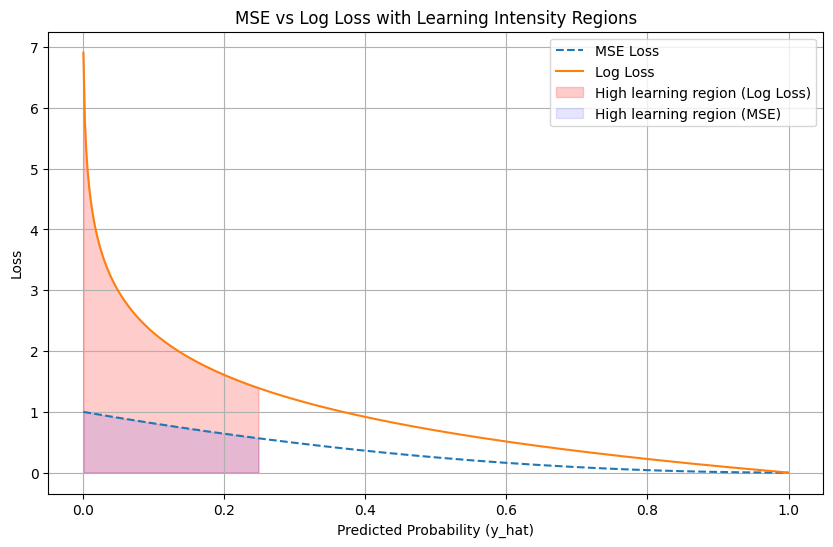

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Predicted probabilities
y_hat = np.linspace(0.001, 0.999, 500)  # avoid log(0)

# True label
y = 1

# Loss functions
mse = (y - y_hat) ** 2
log_loss = -(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

# Gradients (magnitude = how fast it learns)
grad_mse = np.abs(-2 * (y - y_hat))
grad_log = np.abs(-(y / y_hat) + ((1 - y) / (1 - y_hat)))

# Plot
plt.figure(figsize=(10, 6))

# Loss curves
plt.plot(y_hat, mse, label="MSE Loss", linestyle="--")
plt.plot(y_hat, log_loss, label="Log Loss")

# Highlight regions where learning is strong (high gradient)
threshold = np.percentile(grad_log, 75)

high_learning_region = grad_log > threshold

plt.fill_between(
    y_hat,
    log_loss,
    where=high_learning_region,
    color="red",
    alpha=0.2,
    label="High learning region (Log Loss)"
)

plt.fill_between(
    y_hat,
    mse,
    where=grad_mse > np.percentile(grad_mse, 75),
    color="blue",
    alpha=0.1,
    label="High learning region (MSE)"
)

# Labels
plt.title("MSE vs Log Loss with Learning Intensity Regions")
plt.xlabel("Predicted Probability (y_hat)")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [28]:
# Code for logistic regression cost 
import numpy as np

def log_loss(y, y_hat):
    """
    Compute the binary cross-entropy (log loss).

    Parameters
    ----------
    y : np.ndarray of shape (m,) or (m, 1)
        True binary labels (0 or 1)

    y_hat : np.ndarray of shape (m,) or (m, 1)
        Predicted probabilities (values in (0, 1))

    Returns
    -------
    float
        Mean log loss over all samples
    """
    
    # Flatten if needed
    if y.ndim == 2:
        assert y.shape[1] == 1, "y must have shape (m,) or (m, 1)"
        y = y.reshape(-1)
    if y_hat.ndim == 2:
        assert y_hat.shape[1] == 1, "y_hat must have shape (m,) or (m, 1)"
        y_hat = y_hat.reshape(-1)

    # Check matching shapes
    assert y.shape == y_hat.shape, "y and y_hat must have the same shape"

    # Numerical stability (avoid log(0))
    eps = 1e-15
    y_hat = np.clip(y_hat, eps, 1 - eps)

    # Log loss formula
    loss = -np.mean(
        y * np.log(y_hat) +
        (1 - y) * np.log(1 - y_hat)
    )

    return loss

# Regularization

Regularization is a technique used to **reduce overfitting (high variance)** by adding a penalty term to the cost function. It discourages the model from learning overly complex patterns by limiting the size of the weights.

---

## Types of Regularization

### L1 Regularization (Lasso)
L1 adds the sum of absolute values of the weights:

$$
||W|| = \sum |w_{i,j}|
$$

- Encourages **sparsity** (many weights become exactly zero)
- Leads to **simpler and smaller models**
- Useful for **feature selection**

---

### L2 Regularization (Ridge)
L2 adds the sum of squared values of the weights (Frobenius norm):

$$
||W||^2 = \sum w_{i,j}^2
$$

For vectors:

$$
||W||^2 = W^T W
$$

- Penalizes large weights more strongly
- Produces **smooth and stable models**
- **Most commonly used** in practice

---

## How it works?

Original cost function:

$$
J(w,b) = \frac{1}{m} \sum L(y^{(i)}, \hat{y}^{(i)})
$$

With **L2 regularization**:

$$
J(w,b) = \frac{1}{m} \sum L(y^{(i)}, \hat{y}^{(i)}) + \frac{\lambda}{2m} \sum w_i^2
$$

With **L1 regularization**:

$$
J(w,b) = \frac{1}{m} \sum L(y^{(i)}, \hat{y}^{(i)}) + \frac{\lambda}{2m} \sum |w_i|
$$

- $\lambda$ is the **regularization parameter** (hyperparameter)
- Higher $\lambda$ → stronger penalty → simpler model

---

### Effect on Gradient Descent (Weight Decay)

With L2 regularization:

$$
dw^{[l]} = \text{(backprop term)} + \frac{\lambda}{m} w^{[l]}
$$

Update rule:

$$
w^{[l]} = w^{[l]} - \alpha \cdot dw^{[l]}
$$

Substituting:

$$
w^{[l]} = (1 - \frac{\alpha \lambda}{m}) w^{[l]} - \alpha \cdot \text{(backprop term)}
$$

This is called **weight decay**:
- Each step slightly shrinks the weights
- Large weights are penalized more

---

## Why does Regularization reduce overfitting?

### Intuition 1 (Model Simplicity)
- If $\lambda$ is **too large** → a lot of weights ≈ 0 → model becomes very simple (almost linear)
- If $\lambda$ is **well chosen** → only unnecessary weights shrink → better generalization

---

### Intuition 2 (Activation Behavior)
With activation functions like **tanh**:
- Small weights → inputs near 0
- tanh behaves **almost linearly** near 0

So:
- Large $\lambda$ → network becomes more **linear**
- This reduces the ability to overfit complex patterns

---

## Practical Tip

When debugging gradient descent with regularization:
- Plot the **new cost function J (including regularization)**
- It should **decrease monotonically** during training

If you plot the old cost (without regularization), it may not decrease properly.

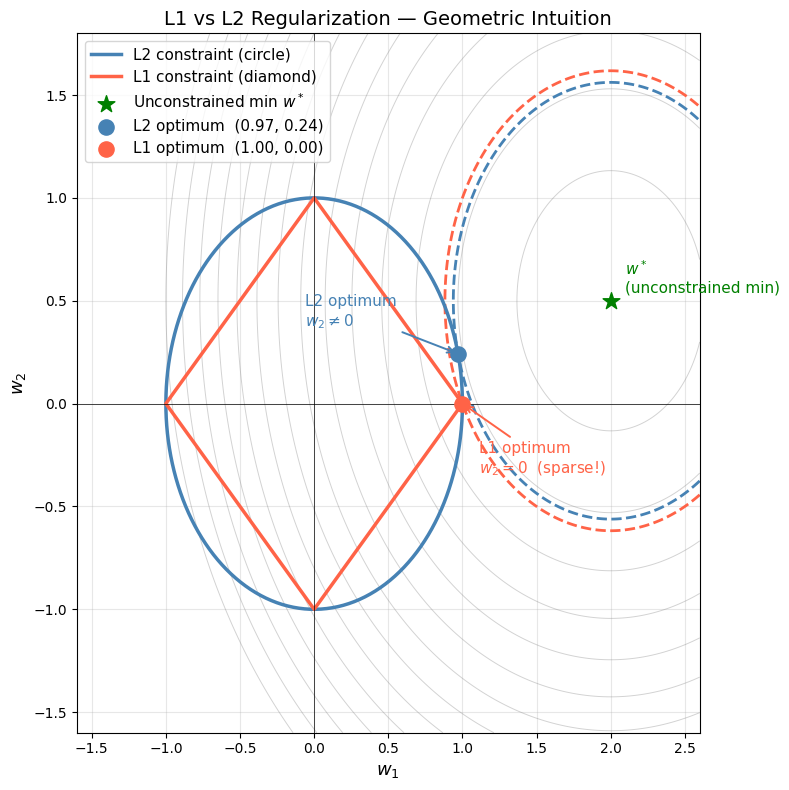

In [29]:
# Visual explanation of L1 vs L2 regularization

import numpy as np
import matplotlib.pyplot as plt

# Unconstrained optimum — sits outside the constraint region
w_star = np.array([2.0, 0.5])

# Cost function: circular contours centred at w_star
w1 = np.linspace(-1.6, 2.6, 400)
w2 = np.linspace(-1.6, 1.8, 400)
W1, W2 = np.meshgrid(w1, w2)
J = (W1 - w_star[0])**2 + (W2 - w_star[1])**2

# Constraint radius
r = 1.0

# --- L2 constraint (circle) ---
theta = np.linspace(0, 2 * np.pi, 500)
l2_x = r * np.cos(theta)
l2_y = r * np.sin(theta)

# L2 optimal: point on circle closest to w_star (projection onto boundary)
# = r * w_star / ||w_star||   =>  approx (0.97, 0.24) — both weights non-zero
l2_point = r * w_star / np.linalg.norm(w_star)

# --- L1 constraint (diamond) ---
l1_vertices = np.array([[r, 0], [0, r], [-r, 0], [0, -r], [r, 0]])

# L1 optimal: corner (r, 0) — verified analytically:
# on the first-quadrant edge  w1 = 1-t, w2 = t,
# dJ/dt = 4t + 1 > 0 for all t >= 0  =>  minimum at t=0, i.e. (1, 0)
# Result: w2 = 0  =>  sparse solution!
l1_point = np.array([r, 0.0])

# Loss value at each tangent point (= level of the touching contour)
j_l2 = float(np.sum((l2_point - w_star) ** 2))
j_l1 = float(np.sum((l1_point - w_star) ** 2))

# --- Plot ---
plt.figure(figsize=(8, 8))

# Background loss contours
plt.contour(W1, W2, J, levels=np.linspace(0.4, 9, 14),
            colors='gray', alpha=0.35, linewidths=0.7)

# Tangent contours (dashed) — just touch the constraint boundaries
plt.contour(W1, W2, J, levels=[j_l2], colors='steelblue', linewidths=2, linestyles='--')
plt.contour(W1, W2, J, levels=[j_l1], colors='tomato',    linewidths=2, linestyles='--')

# Constraint boundaries
plt.plot(l2_x, l2_y,
         color='steelblue', linewidth=2.5, label='L2 constraint (circle)')
plt.plot(l1_vertices[:, 0], l1_vertices[:, 1],
         color='tomato', linewidth=2.5, label='L1 constraint (diamond)')

# Unconstrained minimum w*
plt.scatter(*w_star, color='green', s=160, zorder=5, marker='*',
            label='Unconstrained min $w^*$')
plt.annotate('$w^*$\n(unconstrained min)', w_star,
             textcoords='offset points', xytext=(10, 6),
             color='green', fontsize=11)

# L2 optimal point
plt.scatter(*l2_point, color='steelblue', s=120, zorder=6,
            label=f'L2 optimum  ({l2_point[0]:.2f}, {l2_point[1]:.2f})')
plt.annotate('L2 optimum\n$w_2 \\neq 0$', l2_point,
             textcoords='offset points', xytext=(-110, 20),
             color='steelblue', fontsize=11,
             arrowprops=dict(arrowstyle='->', color='steelblue', lw=1.4))

# L1 optimal point
plt.scatter(*l1_point, color='tomato', s=120, zorder=6,
            label=f'L1 optimum  ({l1_point[0]:.2f}, {l1_point[1]:.2f})')
plt.annotate('L1 optimum\n$w_2 = 0$  (sparse!)', l1_point,
             textcoords='offset points', xytext=(12, -50),
             color='tomato', fontsize=11,
             arrowprops=dict(arrowstyle='->', color='tomato', lw=1.4))

plt.axhline(0, color='k', linewidth=0.5)
plt.axvline(0, color='k', linewidth=0.5)
plt.xlabel('$w_1$', fontsize=13)
plt.ylabel('$w_2$', fontsize=13)
plt.title('L1 vs L2 Regularization — Geometric Intuition', fontsize=14)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, alpha=0.3)
plt.xlim(-1.6, 2.6)
plt.ylim(-1.6, 1.8)
plt.tight_layout()
plt.show()

## Geometric Intuition: What Regularization Actually Does

The **contour lines** in the plot are iso-loss curves of the training cost $J(w)$ — each ring represents a set of weight vectors that achieve the same training error. The innermost ring corresponds to the lowest loss, and the unconstrained optimum $w^*$ sits at the centre (outside the constraint region).

Regularization reframes the optimisation problem as:

> *Find the weight vector with the lowest training loss that still fits inside the constraint region.*

- **L2** enforces $\|w\|_2^2 = w_1^2 + w_2^2 \leq r^2$ — a **circle** in weight space.
- **L1** enforces $\|w\|_1 = |w_1| + |w_2| \leq r$ — a **diamond** in weight space.

The regularized solution $\hat{w}$ is the point where the **smallest possible loss contour just touches the constraint boundary** — i.e. the optimal intersection between the cost surface and the constraint shape.

Because $w^*$ lies outside the feasible region, the solution is pushed inward:

- **L2 (circle):** the boundary is smooth everywhere, so the tangent point lands in the interior of the arc — both weights stay non-zero, and the model is *shrunk* but not *simplified*.
- **L1 (diamond):** the boundary has sharp **corners on the coordinate axes**. A loss contour expanding outward from $w^*$ is geometrically likely to *first* graze the diamond at one of these corners, forcing one or more weights **exactly to zero**. This is the geometric origin of L1's well-known **sparsity** property — it performs automatic feature selection.

Common uses:
- L1 → **feature selection**
- L2 → **weight smoothing**

In [30]:
# Code for regularization

import numpy as np

def compute_cost_with_regularization(y, y_hat, W, lambd=0.1, reg_type="l2"):
    """
    Compute logistic regression cost with L1 or L2 regularization.

    Parameters
    ----------
    y : np.ndarray of shape (m,)
        True labels (0 or 1)

    y_hat : np.ndarray of shape (m,)
        Predicted probabilities (output of sigmoid)

    W : np.ndarray of shape (n,)
        Model weights (bias NOT included)

    lambd : float
        Regularization strength (lambda)

    reg_type : str
        "l1" or "l2"

    Returns
    -------
    float
        Regularized cost value
    """

    assert y.shape == y_hat.shape, "y and y_hat must have same shape"
    assert W.ndim == 1, "W must be a 1D array"

    m = y.shape[0]

    # --- Log loss (data loss) ---
    data_loss = log_loss(y, y_hat)

    # --- Regularization term ---
    if reg_type == "l2":
        reg = (lambd / (2 * m)) * np.sum(W ** 2)

    elif reg_type == "l1":
        reg = (lambd / (2 * m)) * np.sum(np.abs(W))

    else:
        raise ValueError("reg_type must be 'l1' or 'l2'")

    # --- Total cost ---
    cost = data_loss + reg

    return cost

# Dropout

The dropout regularization eliminates some neurons/weights on each iteration based on a probability. For a given layer (for example layer 3), dropout is implemented as follows:

```python
keep_prob = 0.8

d3 = np.random.rand(a3.shape[0], a3.shape[1]) < keep_prob
a3 = np.multiply(a3, d3)
a3 = a3 / keep_prob
```

The mask d3 determines which neurons are kept and which are dropped. After applying it, the activations are divided by keep_prob to compensate for the fact that some activations were set to zero. Without this scaling, the output of the layer would systematically shrink during training, creating a mismatch between training and test behavior.

Dropout can have different keep_prob per layer. The input layer dropout has to be near 1 (or 1 - no dropout) because you don't want to eliminate a lot of features. At test time we don't use dropout. If you implement dropout at test time - it would add noise to predictions.

One downside of dropout is that it makes the cost function less smooth during training. The value of the loss can fluctuate from iteration to iteration, which makes debugging more difficult. A common strategy to verify that everything is working correctly is to temporarily disable dropout (set all keep_prob to 1) and check that the cost decreases monotonically. Once confirmed, dropout can be re-enabled.

---

### Why Dropout Works

Intuitively, dropout works because it prevents neurons from co-adapting too strongly. Since any neuron can be randomly removed at any time, each neuron is forced to learn features that are useful in combination with many different subsets of other neurons. This leads to a more redundant and distributed representation, which typically generalizes better to unseen data.

Another way to think about it is that dropout implicitly trains a large ensemble of subnetworks that share parameters. The final model can be interpreted as an approximation of averaging the predictions of all these subnetworks.

Interestingly, dropout has a regularizing effect similar to L2 regularization, even though the mechanism is completely different. Instead of shrinking weights directly, it injects noise into the network during training, which discourages overly complex co-adaptations.

# Other Regularization Methods

Beyond L1, L2 regularization and dropout, there are several other practical techniques used to reduce overfitting and improve generalization.

One of the most common is **data augmentation**, especially in computer vision tasks. The idea is to artificially increase the size of the training set by applying label-preserving transformations to existing examples. For instance, images can be flipped horizontally to create new valid samples that still represent the same class. Similarly, random rotations, translations, and small distortions can be applied to images to generate additional training data. In tasks such as optical character recognition (OCR), introducing random rotations and elastic distortions of digits or letters can significantly improve robustness.

Although these artificially generated samples are not as informative as truly independent real-world data, they still help reduce overfitting because they expose the model to a wider variety of input variations. In practice, data augmentation acts as a powerful implicit regularizer by making the model less sensitive to small changes in the input.

Another important technique is **early stopping**. During training, both the training set error and the development set error are monitored over iterations. Typically, the training error keeps decreasing, while the development error eventually reaches a minimum and then starts increasing due to overfitting. Early stopping consists of selecting the parameters at the point where the development error is lowest, even if the training error has not fully converged.

This method is effective because it prevents the model from continuing to fit noise in the training data. However, Andrew Ng often notes that L2 regularization is generally preferred over early stopping. The reason is conceptual: early stopping simultaneously tries to minimize training error while also limiting overfitting, which can be seen as coupling two objectives that ideally should be handled separately (this relates to the idea of orthogonalization). L2 regularization, in contrast, cleanly separates these goals by explicitly adding a penalty term to the cost function.

That said, early stopping has a practical advantage: it does not require tuning an additional hyperparameter such as λ in L2 regularization, which can simplify the model selection process.

Finally, another powerful approach is the use of **model ensembles**. The idea is simple: train multiple independent neural networks and average their predictions at test time. This usually leads to improved performance because different models tend to make different errors, and averaging helps reduce variance. In practice, ensembles can improve accuracy by a few percentage points, which can be very significant in competitive settings.

A practical variant of this idea is to take multiple “snapshots” of a single neural network during training and combine them as an ensemble. This allows one to approximate the benefits of ensembling without training completely separate models from scratch. 

# Learning rate decay

It consist in slowly reduce learning rate. As mentioned before mini-batch gradient descent won't reach the optimum point (converge). But by making the learning rate decay with iterations it will be much closer to it because the steps (and possible oscillations) near the optimum are smaller. 

One approach is  <br>

 learning_rate = (1 / (1 + decay_rate * epoch_num)) * learning_rate_0 <br>

when epoch_num is over all data (not a single mini-batch); decay_rate is another hyperparameter. Other learning rate decay methods (continuous): <br>

learning_rate = (0.95 ^ epoch_num) * learning_rate_0 <br>
learning_rate = (k / sqrt(epoch_num)) * learning_rate_0 <br>

Some people perform learning rate decay discretely - repeatedly decrease after some number of epochs. Some people are making changes to the learning rate manually.
For some guides, learning rate decay has less priority.

## The problem of local optima

The normal local optima is not likely to appear in a deep neural network because data is usually high dimensional. For point to be a local optima it has to be a local optima for each of the dimensions which is highly unlikely. It's unlikely to get stuck in a bad local optima in high dimensions, it is much more likely to get to the saddle point rather to the local optima, which is not a problem.

Plateaus can make learning slow:
- Plateau is a region where the derivative is close to zero for a long time.
- This is where algorithms like momentum, RMSprop or Adam can help.